# Exploring benchmark data

## Benchmark data description

Each mat file from data/benchmark contains a session recording from a specific person. The data is 4D matrix with shape [64, 1500, 40, 6]. The four dimensions are: electrode index, time point, target index, block index. The data was downsampled to 250Hz.

In [13]:
from scipy.io import loadmat
from ssvep import config
import numpy as np

mat = loadmat(config.BENCHMARK_DIR / "S1.mat")


print(mat.keys())

print(mat['data'].shape)


freq_mat = loadmat(config.BENCHMARK_DIR / "Freq_Phase.mat")

print(freq_mat.keys())

print(freq_mat['freqs'].shape)
print(freq_mat['phases'].shape)

freqs = freq_mat['freqs'][0]
phases = freq_mat['phases'][0]

for i in range(40):
    print(f"Target {i}: freq = {freqs[i]}, phase = {phases[i]}")

dict_keys(['__header__', '__version__', '__globals__', 'data'])
(64, 1500, 40, 6)
dict_keys(['__header__', '__version__', '__globals__', 'phases', 'freqs'])
(1, 40)
(1, 40)
Target 0: freq = 8.0, phase = 0.0
Target 1: freq = 9.0, phase = 1.5707963267948966
Target 2: freq = 10.0, phase = 3.141592653589793
Target 3: freq = 11.0, phase = 4.71238898038469
Target 4: freq = 12.0, phase = 0.0
Target 5: freq = 13.0, phase = 1.5707963267948966
Target 6: freq = 14.0, phase = 3.141592653589793
Target 7: freq = 15.0, phase = 4.71238898038469
Target 8: freq = 8.2, phase = 1.5707963267948966
Target 9: freq = 9.2, phase = 3.141592653589793
Target 10: freq = 10.2, phase = 4.71238898038469
Target 11: freq = 11.2, phase = 0.0
Target 12: freq = 12.200000000000001, phase = 1.5707963267948966
Target 13: freq = 13.200000000000001, phase = 3.141592653589793
Target 14: freq = 14.200000000000001, phase = 4.71238898038469
Target 15: freq = 15.200000000000001, phase = 0.0
Target 16: freq = 8.4, phase = 3.14159265

## Epoching the data

If we look at 64-channels.loc we can see that index of o1 channel is 62 but since it is indexed from 1, we'll use 61 in the code below.

In [16]:
data = mat["data"]
fs = config.BENCHMARK_FS

# Which position do we want on each axis?
ch = 61
target = 2
print("frequency of this target:", freqs[target])

# Time window: from when the SSVEP reaches the cortex until the flicker stops.
# Times count from the start of the epoch, which is 0.5 s before the flicker starts.
t_start = config.BENCHMARK_ONSET + config.BENCHMARK_LATENCY
t_stop = config.BENCHMARK_ONSET + 5.0
start = int(round(t_start * fs))
stop = int(round(t_stop * fs))
print("samples", start, "to", stop)

# data[channel, time, target, block]
x = data[ch, start:stop, target, 0]
print("one block:", x.shape)

x_blocks = data[ch, start:stop, target, :]
print("all blocks:", x_blocks.shape)

frequency of this target: 10.0
samples 160 to 1375
one block: (1215,)
all blocks: (1215, 6)


## Welch method

Why is FFT not enough? If we calculate FFT for a large chunk of data then the more data we add the noisier the result will be. The solution to that problem is welch method that divides the signal into segments, applies Hann window, calculates FFT on each segment and averages the results. Below we will plot 3 curves:
- welch method on single trial
- welch method on all 6 trials, and calculate average
- calculate average of 6 trials then apply welch method

(251,) (251,)
(251,) (251, 6)
(251,)
(1215,)
(251,) (251,)


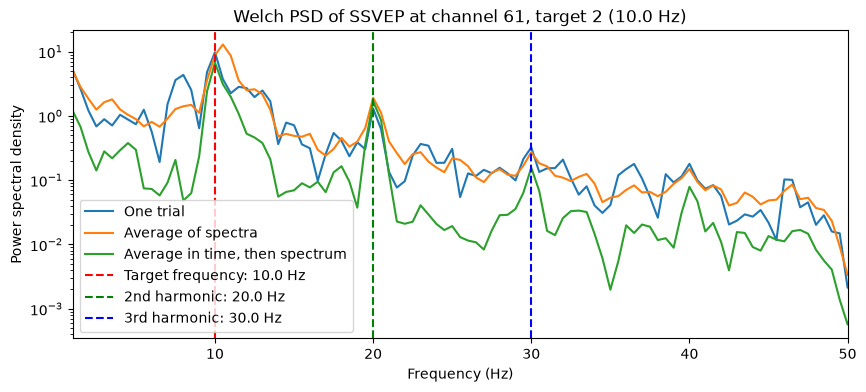

In [42]:
import matplotlib.pyplot as plt
from scipy.signal import welch

f_single, pxx_single = welch(x, fs=fs, nperseg=500, axis=0)
f_all, pxx_all = welch(x_blocks, fs=fs, nperseg=500, axis=0)
print(f_single.shape, pxx_single.shape)
print(f_all.shape, pxx_all.shape)


pxx_all_mean = np.mean(pxx_all, axis=1)
print(pxx_all_mean.shape)

x_blocks_mean = np.mean(x_blocks, axis=1)
print(x_blocks_mean.shape)

f_all_mean, pxx_all_mean2 = welch(x_blocks_mean, fs=fs, nperseg=500, axis=0)
print(f_all_mean.shape, pxx_all_mean2.shape)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(f_single, pxx_single, label="One trial")
ax.plot(f_all, pxx_all_mean, label="Average of spectra")
ax.plot(f_all_mean, pxx_all_mean2, label="Average in time, then spectrum")
ax.semilogy()
ax.set_xlim(1, 50)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Power spectral density")
ax.set_title(f"Welch PSD of SSVEP at channel {ch}, target {target} ({freqs[target]} Hz)")
ax.axvline(freqs[target], color='r', linestyle='--', label=f"Target frequency: {freqs[target]} Hz")
ax.axvline(freqs[target] * 2, color='g', linestyle='--', label=f"2nd harmonic: {freqs[target]*2} Hz")
ax.axvline(freqs[target] * 3, color='b', linestyle='--', label=f"3rd harmonic: {freqs[target]*3} Hz")
ax.legend()
plt.show()

config.RESULTS_DIR.mkdir(exist_ok=True)
fig.savefig(config.RESULTS_DIR / "s1_oz_10hz_psd.png", dpi=150)



## Interpreting results

### One trial

we can see a lot of noise, that is also what our BCI system will see online, just one trial and it has to decide. we can still see clear spikes at 10hz and its harmonics, but there are a lot of other spikes that could potentially be misinterpreted

### Average of spectra

is much smoother, however, floor is still very high, a spectrum stores only power (which is always positive) so when we calculate the average of 6 spectra the noise cannot cancel out.

### Average in time, then spectrum

floor is way lower since we first calculate average of all 6 trials, the noise cancels out. This is important because that is what TRCA will be based on later on